In [1]:
import torch
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from transformers import WhisperProcessor, WhisperForConditionalGeneration

/opt/anaconda3/envs/keras/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1105 12:44:26.417000 15482 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


# 1. Liiketoiminnan ymmärtäminen

# 2. Datan ymmärtäminen

Datana on yhteensä 17 suomenkielistä ääninäytettä, joista 8 on ladattu [Mozilla Common Voice -aineistosta](https://mozilladatacollective.com/datasets/cmu5vgfuk00aunq07xzlhzvxg) ja 9 on itse äänitettyjä. Kuulon perusteella on arvioitu, onko puhuja mies, nainen vai lapsi, sekä litteroitu, mitä äänitteessä oikeasti sanotaan. Litterointeja käytetään myöhemmin Whisper-mallien tunnistustulosten vertailuun.

Omia ääninäytteitä otin sekä selkeissä olosuhteissa että taustakohinan kanssa, kuten vesihanan ja pyykkikoneen äänen kuuluessa. Lisäksi yhdessä äänitteessä käytetään murteellista puhetta. Yhteensä 14 äänitettä on selkeitä ja kolmessa on taustahälyä. Kaikki `oma_*`-äänitteet ovat Elias Rinteen puhumia.

Alla olevassa taulukossa on esitetty käytetyt äänitteet, niiden kuvaukset ja litteroinnit.

| Tiedoston nimi | Kuvailu | Mitä äänitteessä sanotaan (litterointi) |
|---|---|---|
| common_voice_fi_22986631.mp3 | Ladattu ääni, mies, selkeä | Mitä nyt tekisimme? |
| common_voice_fi_25286493.mp3 | Ladattu ääni, mies, selkeä | Niillä ansioilla ostettuja kelloja |
| common_voice_fi_25299325.mp3 | Ladattu ääni, nainen, selkeä | Nousin ylös olennon vierestä ja kävelin ohjaamoa kohti. |
| common_voice_fi_25299573.mp3 | Ladattu ääni, nainen, selkeä | Äänestin myös ensimmäistä rautatiepakettia vastaan. |
| common_voice_fi_30419449.mp3 | Ladattu ääni, nainen, selkeä | Äänestimme puolesta korjataksemme tehdyn virheen. |
| common_voice_fi_32682465.mp3 | Ladattu ääni, nainen, selkeä | Samaan aikaan mahdollistetaan työmatkaliikenne sisärajoilla vastaavalla tavalla kuin toimitaan länsi- ja pohjoisrajoilla. |
| common_voice_fi_49679457.mp3 | Ladattu ääni, lapsi (tyttö), selkeä | Äänestin mietintöä vastaan. |
| common_voice_fi_49679459.mp3 | Ladattu ääni, lapsi (tyttö), selkeä | Ville oli ihmeissään. |
| oma_1.m4a | Oma äänite, mies, selkeä | Kiva on kivaa kakka on kakkaa. |
| oma_10_korkea.m4a | Oma äänite, mies, selkeä, korkea | Ville oli ihmeissään. |
| oma_11_matala.m4a | Oma äänite, mies, selkeä, matala | Ville oli ihmeissään. |
| oma_2.m4a | Oma äänite, mies, selkeä | Paljon tekstiä paljon sähinää. Jee. |
| oma_3.m4a | Oma äänite, mies, selkeä | Joskus vois tehä toisinaan taas ei. |
| oma_4.m4a | Oma äänite, mies, selkeä | Mulla on tylsää. Äänittäminen on tylsää. |
| oma_5.m4a | Oma äänite, mies, selkeä | Joskus vois tehä asiat toisin. Mutta ei tällä kertaa. |
| oma_6_vesi.m4a | Oma äänite, mies, taustahäly: vesihana | Otetaan vähän taustakohinaa mukaan. Kivasti lavuaari vuotaa. |
| oma_7_vesi.m4a | Oma äänite, mies, taustahäly: vesihana | Otetaan toinen samanlainen. Vähän lisää tätä vettä. Jee. |
| oma_8_pyykki.m4a | Oma äänite, mies, taustahäly: pyykkikone | Vähän lisää pyykinpesu mukana tässä. Jee. |
| oma_9_murre.m4a | Oma äänite, mies, murteellinen puhe, selkeä | Tokkopa ny mikkää mennee pieleen. |


# 3. Datan valmistelu

## 3.1 Esivalmistellaan data librosalla
Ensin muutetaan ääninäytteet lukujonoiksi käyttäen librosaa. Tällöin saadaan äänitteet käsiteltävään muotoon WHisperProcessorille.

In [2]:
from pathlib import Path
import librosa

# .mp3 on ladatut ja .m4a on macbookilla äänitetyt
suffixes = [".mp3", ".m4a"]

audio_dir = Path("aanitteet")
dataset = []

for file in sorted(audio_dir.iterdir()):
    if file.suffix.lower() not in suffixes:    # tarkistaa että pääte kuuluu päätejoukkoon jatkaakseen
        continue

    audio, sr = librosa.load(file, sr=16000)   # Lukee äänen lukujonoksi ja muuntaa näytteenottotaajuuden 16 000 Hz:iin

    dataset.append({
        "filename": file.name,
        "audio": audio,
        "sample_rate": sr
    })

print(f"Ladattu {len(dataset)} äänitettä\n")

print("Datasetti kokonaisuudessaan:")
for data in dataset:
    print(f"\n{data['filename']}: {len(data['audio']) / data['sample_rate']:.2f} s")

Ladattu 19 äänitettä

Datasetti kokonaisuudessaan:

common_voice_fi_22986631.mp3: 4.78 s

common_voice_fi_25286493.mp3: 3.46 s

common_voice_fi_25299325.mp3: 5.94 s

common_voice_fi_25299573.mp3: 4.97 s

common_voice_fi_30419449.mp3: 5.69 s

common_voice_fi_32682465.mp3: 9.00 s

common_voice_fi_49679457.mp3: 2.70 s

common_voice_fi_49679459.mp3: 2.81 s

oma_1.m4a: 4.31 s

oma_10_korkea.m4a: 2.07 s

oma_11_matala.m4a: 3.09 s

oma_2.m4a: 5.03 s

oma_3.m4a: 3.48 s

oma_4.m4a: 3.52 s

oma_5.m4a: 4.91 s

oma_6_vesi.m4a: 5.42 s

oma_7_vesi.m4a: 5.63 s

oma_8_pyykki.m4a: 5.16 s

oma_9_murre.m4a: 3.75 s


/var/folders/wh/9dhw52gj7c18zhl8y4z0dy9w0000gn/T/ipykernel_15482/4265550120.py:14: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(file, sr=16000)   # Lukee äänen lukujonoksi ja muuntaa näytteenottotaajuuden 16 000 Hz:iin
/opt/anaconda3/envs/keras/lib/python3.11/site-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


## 3.2 Mel spektogrammi ekalle näytteelle

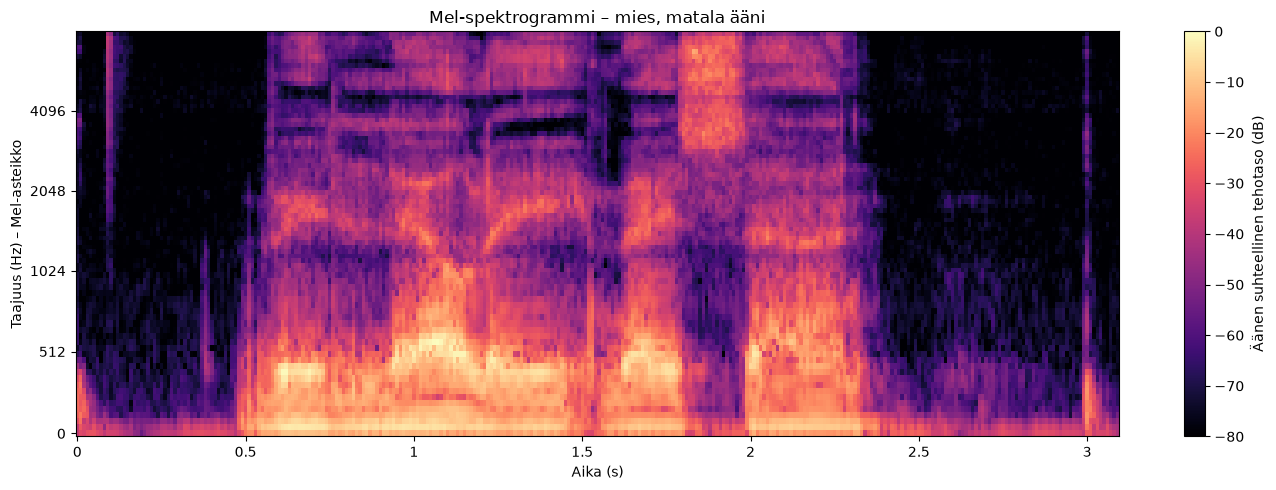

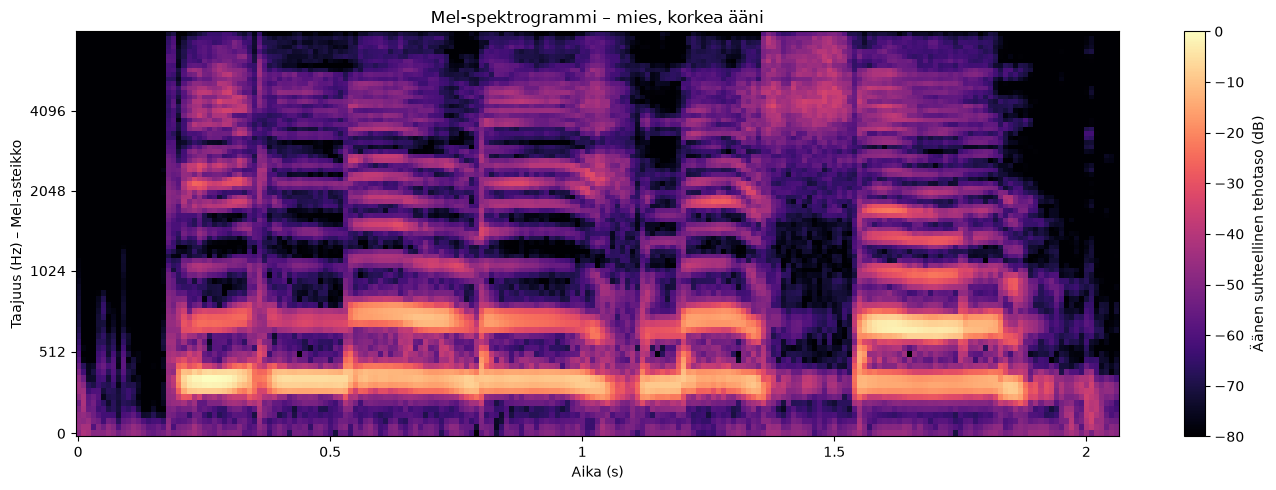

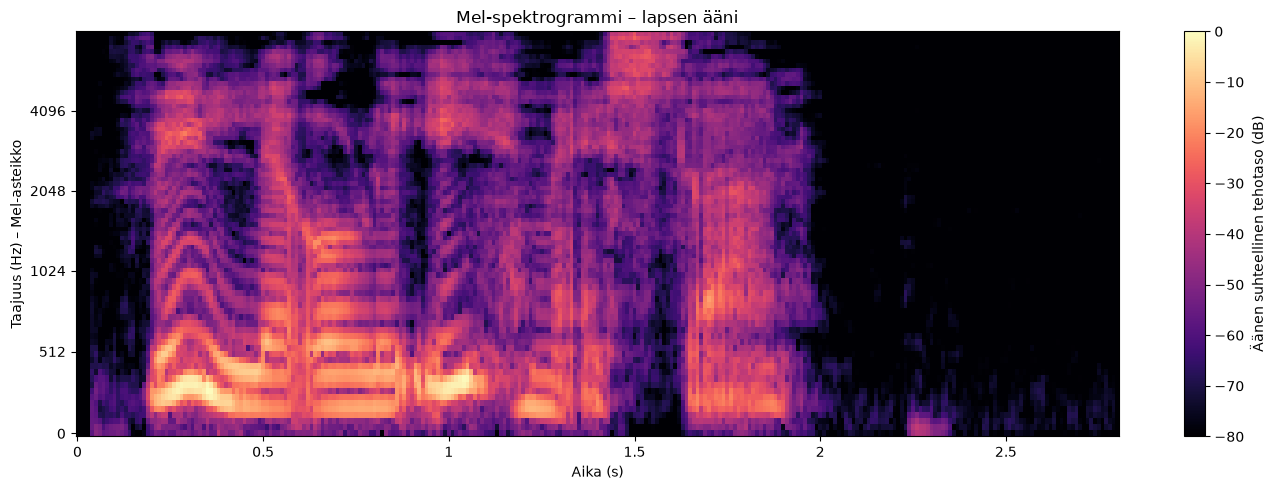

In [3]:
# Valitut ääninäytteet mies matala, mies korkea ja lapsi

# Matalampi miehen ääni
sample_deep = next(sample for sample in dataset if sample["filename"] == "oma_11_matala.m4a")
audio_deep = np.asarray(sample_deep["audio"])
sr_deep = sample_deep["sample_rate"]

# Korkea miehen ääni
sample_high = next(sample for sample in dataset if sample["filename"] == "oma_10_korkea.m4a")
audio_high = np.asarray(sample_high["audio"])
sr_high = sample_high["sample_rate"]

# Lapsen ääni
sample_child = next(sample for sample in dataset if sample["filename"] == "common_voice_fi_49679459.mp3")
audio_child = np.asarray(sample_child["audio"])
sr_child = sample_child["sample_rate"]


# Mel-spektrogrammi miehelle matala
mel_deep = librosa.feature.melspectrogram(
    y=audio_deep,
    sr=sr_deep,
    n_fft=400,
    hop_length=160,
    win_length=400,
    n_mels=80,
    fmax=8000
)

# Mel-spektrogrammi miehelle korkea
mel_high = librosa.feature.melspectrogram(
    y=audio_high,
    sr=sr_high,
    n_fft=400,
    hop_length=160,
    win_length=400,
    n_mels=80,
    fmax=8000
)

# Mel-spektrogrammi lapselle
mel_child = librosa.feature.melspectrogram(
    y=audio_child,
    sr=sr_child,
    n_fft=400,
    hop_length=160,
    win_length=400,
    n_mels=80,
    fmax=8000
)

# Muunnetaan teho desibeleiksi
mel_db_deep = librosa.power_to_db(mel_deep, ref=np.max)
mel_db_high = librosa.power_to_db(mel_high, ref=np.max)
mel_db_child = librosa.power_to_db(mel_child, ref=np.max)


# Kuvaaja matala
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    mel_db_deep,
    sr=sr_deep,
    hop_length=160,
    x_axis="time",
    y_axis="mel",
    cmap="magma",
    vmin=-80,
    vmax=0
)

plt.colorbar(label="Äänen suhteellinen tehotaso (dB)")
plt.title("Mel-spektrogrammi – mies, matala ääni")
plt.xlabel("Aika (s)")
plt.ylabel("Taajuus (Hz) – Mel-asteikko")

plt.tight_layout()
plt.show()

print("")

# Kuvaaja korkea
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    mel_db_high,
    sr=sr_high,
    hop_length=160,
    x_axis="time",
    y_axis="mel",
    cmap="magma",
    vmin=-80,
    vmax=0
)

plt.colorbar(label="Äänen suhteellinen tehotaso (dB)")
plt.title("Mel-spektrogrammi – mies, korkea ääni")
plt.xlabel("Aika (s)")
plt.ylabel("Taajuus (Hz) – Mel-asteikko")

plt.tight_layout()
plt.show()

print("")

# Kuvaaja lapsi
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    mel_db_child,
    sr=sr_child,
    hop_length=160,
    x_axis="time",
    y_axis="mel",
    cmap="magma",
    vmin=-80,
    vmax=0
)

plt.colorbar(label="Äänen suhteellinen tehotaso (dB)")
plt.title("Mel-spektrogrammi – lapsen ääni")
plt.xlabel("Aika (s)")
plt.ylabel("Taajuus (Hz) – Mel-asteikko")

plt.tight_layout()
plt.show()

### 3.2.1 Spektrogrammin tulkinta

X-akseli kuvaa ääninäytteen etenemistä sekunneissa. Y-akseli kuvaa äänen taajuuksia Mel-asteikolla. Matalammat hertsilukemat vastaavat matalampia taajuuksia ja suuremmat hertsilukemat korkeampia taajuuksia. Väri kertoo äänen suhteellisen tehon desibeleinä tietyllä taajuusalueella. Mitä vaaleampi väri on, sitä enemmän äänen energiaa kyseisellä alueella esiintyy. Spektrogrammit kuvaa sitä, miten äänen taajuusrakenne muuttuu eri puhetavoilla. Ensimmäiset, omat näytteet, ovat monotonisia ja viimeinen lapsen näyte sisältää vaihtelua.

Matalan ja korkean äänen spektrogrammeissa näkyy selkeitä eroja, vaikka molemmissa sanotaan sama lause. Matalan äänen näytteessä energiaa esiintyy laajasti eri taajuuksilla, myös yli 4000 hertsin alueella. Tämä ei kuitenkaan tarkoita, että äänen perustaajuus olisi näin korkea.

Korkean äänen spektrogrammissa näkyy selkeämmin vaakasuuntaisia taajuusjuovia. Niiden välinen etäisyys liittyy äänen perustaajuuteen. Korkeammalla äänellä puhuttaessa perustaajuus on yleensä suurempi kuin matalalla äänellä puhuttaessa.

## 3.3 Prosessoidaan data Whisperille

Prosessoidaan data Whisperille käyttäen WhisperPreprocess. WhisperProcessor myös tokenisoi tekstin. Kokeilen malleja tiny, small, base, medium, large V3 ja turbo.
### 3.2.1 Ladataan mallit tokenilla (nopeempi) tai ilman.

In [4]:
from transformers import WhisperProcessor
import os

models = {}

# Tarkistetaan token
hf_token = os.environ.get("HF_TOKEN")

if hf_token:
    print("Token löytyi.")
else:
    print("Tokenia ei löytynyt. Tarkista onko token syötetty oikeaan ympäristöön (esim keras ympäristöön)")

# Käytetään tokenia jos löytyy, jos ei menee tokenitta
models["tiny"] = WhisperProcessor.from_pretrained("openai/whisper-tiny", token=hf_token)
models["small"] = WhisperProcessor.from_pretrained("openai/whisper-small", token=hf_token)
models["base"] = WhisperProcessor.from_pretrained("openai/whisper-base", token=hf_token)
models["medium"] = WhisperProcessor.from_pretrained("openai/whisper-medium", token=hf_token)
# tän hetkinen tarkin malli V3, minkä löysin, mutta raskas
models["large"] = WhisperProcessor.from_pretrained("openai/whisper-large-v3", token=hf_token) 
# optimoitu large v3 malli, mutta hieman heikompi tarkkuus
models["turbo"] = WhisperProcessor.from_pretrained("openai/whisper-large-v3-turbo", token=hf_token)

Token löytyi.


### 3.2.2 Mel-spektogrammit vain tiny mallilla

Prosessoidaan kaikki näytteet, mutta tarkastellaan vain ensimmäistä vertailun vuoksi (common_voice_fi_22986631.mp3, ladattu ääni, mies, selkeä).

In [5]:
samples = {}

In [6]:
samples_tiny = []
for sample in dataset:
    features = models["tiny"](
        sample["audio"],
        sampling_rate=sample["sample_rate"],
        return_tensors="pt"
    ).input_features

    samples_tiny.append(features[0])
    
samples["tiny"] = samples_tiny

mel_tiny = samples["tiny"][0]
print(mel_tiny.shape)

torch.Size([80, 3000])


# 4. Mallintaminen

# 5. Evaluointi

# 6. Käyttöönotto